In [1]:
source(file = "..//Libraries.R") |> suppressWarnings() |>  suppressMessages() 

In [165]:
data_mortality <- read.csv("..//data//owid_child_mortality.csv")
data_poverty <- read.csv("..//data//owid_poverty_lines.csv")
data_pip <- read.csv("..//data//worldbank_pip.csv")

In [166]:
head(data_poverty)
head(data_mortality)

,Country,Year,Share.below..1.a.day,Share.below..3.a.day,Share.below..4.20.a.day,Share.below..8.30.a.day,Share.below..10.a.day,Share.below..20.a.day,Share.below..30.a.day,Share.below..40.a.day
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Albania,1996,0.00000000,2.9678411,11.875356,58.61190,71.59013,98.21732,99.78631,99.91247
2,Albania,2002,0.04637062,4.1947220,15.062597,60.98380,73.17924,95.70540,98.74161,99.72257
3,Albania,2005,0.00000000,2.6502175,9.422840,49.99293,64.41114,94.31050,98.56845,99.51416
4,Albania,2008,0.00000000,0.8273079,5.876955,43.44341,58.71617,93.57756,98.16591,99.21715
5,Albania,2012,0.02410076,1.7945902,6.535600,45.90034,60.39007,94.31484,98.69061,99.65560
6,Albania,2014,0.00000000,3.6761396,12.498381,46.49271,57.36491,89.56094,97.57758,99.25326


,entity,code,year,child_mortality_rate
,<chr>,<chr>,<int>,<dbl>
1,Afghanistan,AFG,1957,36.82
2,Afghanistan,AFG,1958,36.21
3,Afghanistan,AFG,1959,35.64
4,Afghanistan,AFG,1960,35.06
5,Afghanistan,AFG,1961,34.52
6,Afghanistan,AFG,1962,34.02


In [ ]:
data_poverty %>%
    rename(year = Year) %>%
    group_by(Country) %>%
    summarise(
        min = min(year),
        max = max(year)
    )
data_mortality %>%
    rename(Country = entity) %>%
    group_by(Country) %>% #here tibble-ing happens
    summarise(
        min = min(year),
        max = max(year)
    )



In [14]:
lines <- colnames(data_poverty)[-c(1,2)]
lines

[1] "Share.below..1.a.day"    "Share.below..3.a.day"   
[3] "Share.below..4.20.a.day" "Share.below..8.30.a.day"
[5] "Share.below..10.a.day"   "Share.below..20.a.day"  
[7] "Share.below..30.a.day"   "Share.below..40.a.day"

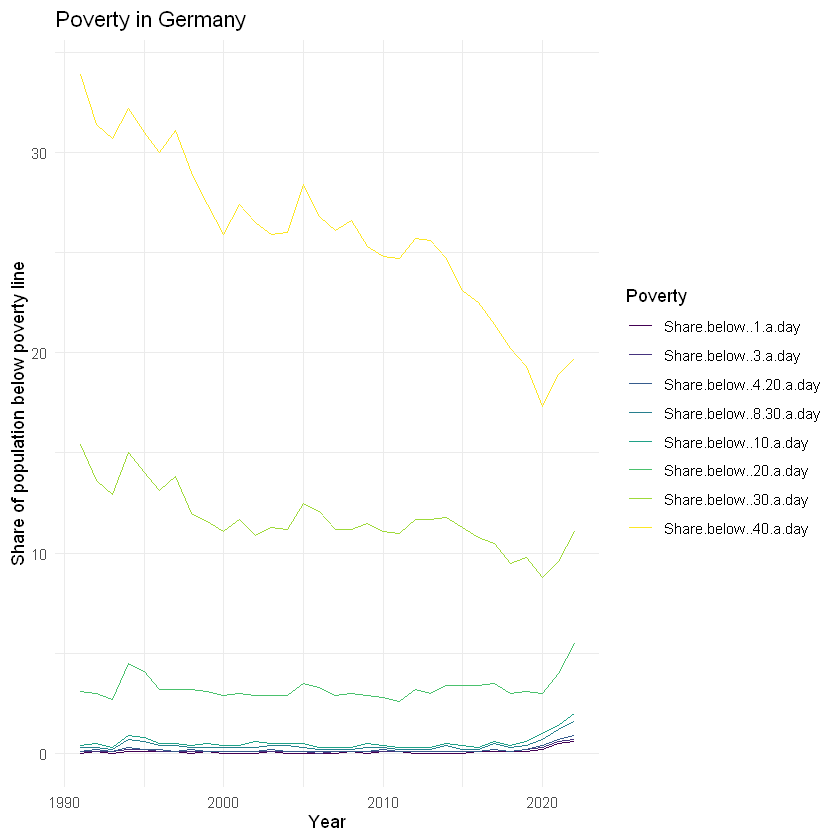

In [15]:
data_poverty %>%
    filter(Country == "Germany") %>%
    pivot_longer(cols = starts_with("Share.below"), names_to = "Poverty", values_to = "share") %>%
    mutate(Poverty = factor(Poverty, levels = lines, ordered = T)) %>%
    ggplot(aes(x = Year, y = share, color = Poverty)) +
    geom_line() +
    theme_minimal() +
    labs(title = "Poverty in Germany",
         x = "Year",
         y = "Share of population below poverty line")


In [53]:
head(data_pip)


,region_name,region_code,country_name,country_code,reporting_year,reporting_level,survey_acronym,survey_coverage,survey_year,welfare_type,⋯,reporting_pop,reporting_gdp,reporting_pce,is_interpolated,distribution_type,estimation_type,spl,spr,pg,estimate_type
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
1,Sub-Saharan Africa,SSF,Angola,AGO,2000,national,HBS,national,2000.21,consumption,⋯,16310860,2172.463,NA,FALSE,micro,survey,3.950,0.3714692,9.609202,NA
2,Sub-Saharan Africa,SSF,Angola,AGO,2008,national,IBEP-MICS,national,2008.50,consumption,⋯,21996714,3559.195,1748.428,FALSE,micro,survey,3.967,0.3533580,6.838756,NA
3,Sub-Saharan Africa,SSF,Angola,AGO,2018,national,IDREA,national,2018.17,consumption,⋯,31480496,3196.790,2261.456,FALSE,micro,survey,3.240,0.4216190,10.964242,NA
4,Europe & Central Asia,ECS,Albania,ALB,1996,national,EWS,national,1996.00,consumption,⋯,3168033,1683.770,1522.872,FALSE,micro,survey,5.010,0.2039019,4.209428,NA
5,Europe & Central Asia,ECS,Albania,ALB,2002,national,LSMS,national,2002.00,consumption,⋯,3051010,2297.109,1572.295,FALSE,micro,survey,4.859,0.2244040,4.429310,NA
6,Europe & Central Asia,ECS,Albania,ALB,2005,national,LSMS,national,2005.00,consumption,⋯,3011487,2712.870,1969.242,FALSE,micro,survey,5.450,0.2099751,3.860997,NA


In [24]:
colnames(data_pip)
data_pip$poverty_line |> unique()

[1] "region_name"          "region_code"          "country_name"        
 [4] "country_code"         "reporting_year"       "reporting_level"     
 [7] "survey_acronym"       "survey_coverage"      "survey_year"         
[10] "welfare_type"         "survey_comparability" "comparable_spell"    
[13] "poverty_line"         "headcount"            "poverty_gap"         
[16] "poverty_severity"     "watts"                "mean"                
[19] "median"               "mld"                  "gini"                
[22] "polarization"         "decile1"              "decile2"             
[25] "decile3"              "decile4"              "decile5"             
[28] "decile6"              "decile7"              "decile8"             
[31] "decile9"              "decile10"             "cpi"                 
[34] "ppp"                  "reporting_pop"        "reporting_gdp"       
[37] "reporting_pce"        "is_interpolated"      "distribution_type"   
[40] "estimation_type"      "spl"                  "spr"                 
[43] "pg"                   "estimate_type"

[1] 3

In [77]:
head(data_pip %>% filter(country_name == "China"))

,region_name,region_code,country_name,country_code,reporting_year,reporting_level,survey_acronym,survey_coverage,survey_year,welfare_type,⋯,reporting_pop,reporting_gdp,reporting_pce,is_interpolated,distribution_type,estimation_type,spl,spr,pg,estimate_type
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<dbl>,<chr>,⋯,<dbl>,<dbl>,<dbl>,<lgl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<lgl>
1,East Asia & Pacific,EAS,China,CHN,1981,national,CRHS-CUHS,national,1981,income,⋯,993885000,453.0727,NA,FALSE,synthetic,survey,3,0.9700409,27.48521,NA
2,East Asia & Pacific,EAS,China,CHN,1981,rural,CRHS-CUHS,national,1981,income,⋯,793552685,453.0727,NA,FALSE,group,survey,3,0.9895000,30.68436,NA
3,East Asia & Pacific,EAS,China,CHN,1981,urban,CRHS-CUHS,national,1981,income,⋯,200332315,453.0727,NA,FALSE,group,survey,3,0.8929600,14.78243,NA
4,East Asia & Pacific,EAS,China,CHN,1984,national,CRHS-CUHS,national,1984,income,⋯,1036825000,604.3540,NA,FALSE,synthetic,survey,3,0.9125456,20.36223,NA
5,East Asia & Pacific,EAS,China,CHN,1984,rural,CRHS-CUHS,national,1984,income,⋯,798207307,604.3540,NA,FALSE,group,survey,3,0.9445700,22.53993,NA
6,East Asia & Pacific,EAS,China,CHN,1984,urban,CRHS-CUHS,national,1984,income,⋯,238617693,604.3540,NA,FALSE,group,survey,3,0.8054200,12.73182,NA


In [56]:
data %>% filter(country_name == "China", welfare_type == "consumption") %>% head()

    

,country_name,reporting_year,headcount,gini,reporting_level,welfare_type,mld,reporting_pop
,<chr>,<int>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
1,China,1990,0.8310968,0.3222662,national,consumption,0.1694444,1135185000
2,China,1990,0.9137600,0.3047581,rural,consumption,0.1555835,837815325
3,China,1990,0.5982000,0.2559464,urban,consumption,0.1057551,297369675
4,China,1993,0.7728333,0.3387780,national,consumption,0.1852071,1178440000
5,China,1993,0.9050500,0.2804393,rural,consumption,0.1283627,848593748
6,China,1993,0.4326800,0.2846636,urban,consumption,0.1312918,329846252


In [ ]:
data %>% 
    filter(country_name == "China", welfare_type == "consumption") %>%
    pivot_longer(cols = c(headcount, gini), names_to = "variable", values_to = "value") %>%
    ggplot(aes(x = reporting_year, y = value, color = reporting_level, linetype = variable)) +
    geom_line() +
    theme_minimal() +
    labs(title = "Poverty in China",
         x = "Year",
         y = "Value")

Ab hier gehts los

In [130]:
source(file = "..//Libraries.R") |> suppressWarnings() |>  suppressMessages() 
data_pip <- read.csv("..//data//worldbank_pip.csv")
data_China <- data_pip %>% 
    filter(country_name == "China") %>%
    select(country_name,
        reporting_year, headcount, gini, reporting_level, mld, reporting_pop)

year_change <- 1988.5 #last year of income as welfare_type is 1987, consumption starts 1990

shares <- data_China %>% 
    select(reporting_year, reporting_level, reporting_pop, mld) %>%
    pivot_wider(names_from = reporting_level, values_from = c(reporting_pop, mld)) %>%
    mutate(p_rural = reporting_pop_rural/reporting_pop_national, p_urban = reporting_pop_urban/reporting_pop_national, p_national = 1) %>%
    mutate(mld_within = mld_rural*p_rural + mld_urban*p_urban) %>%
    mutate(mld_between = mld_national - mld_within) %>% 
    select(-c(reporting_pop_national, reporting_pop_rural, reporting_pop_urban, mld_rural, mld_urban)) %>%
    rename(mld_total = mld_national)
data_mld <- shares %>% select(reporting_year, mld_total, mld_within, mld_between) %>%
    mutate(share_between = mld_between/mld_total)
shares <- shares %>% select(-c(mld_total, mld_within, mld_between))
shares <- shares %>% pivot_longer(cols = c(p_rural, p_urban, p_national),
    names_to = "reporting_level", values_to = "pop_share") %>%
    mutate(reporting_level = factor(reporting_level,
    levels = c("p_national", "p_rural", "p_urban"), labels = c("national", "rural", "urban")))
data_China <- inner_join(data_China, shares, by = c("reporting_year", "reporting_level"))
head(data_mld)
head(data_China)
str(data_mld)
str(data_China)

reporting_year,mld_total,mld_within,mld_between,share_between
<int>,<dbl>,<dbl>,<dbl>,<dbl>
1981,0.1283629,0.09072256,0.03764033,0.2932337
1984,0.1196984,0.10040291,0.01929552,0.1612011
1987,0.1436242,0.12313051,0.02049370,0.1426898
1990,0.1694444,0.14253057,0.02691387,0.1588360
1993,0.1852071,0.12918256,0.05602451,0.3024966
1996,0.2014144,0.16883655,0.03257780,0.1617452


,country_name,reporting_year,headcount,gini,reporting_level,mld,reporting_pop,pop_share
,<chr>,<int>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
1,China,1981,0.9700409,0.2816410,national,0.12836289,993885000,1.0000000
2,China,1981,0.9895000,0.2472923,rural,0.09959756,793552685,0.7984351
3,China,1981,0.8929600,0.1850883,urban,0.05556710,200332315,0.2015649
4,China,1984,0.9125456,0.2710230,national,0.11969843,1036825000,1.0000000
5,China,1984,0.9445700,0.2668613,rural,0.11548614,798207307,0.7698573
6,China,1984,0.8054200,0.1774405,urban,0.04994753,238617693,0.2301427


tibble [23 × 5] (S3: tbl_df/tbl/data.frame)
 $ reporting_year: int [1:23] 1981 1984 1987 1990 1993 1996 1999 2002 2005 2008 ...
 $ mld_total     : num [1:23] 0.128 0.12 0.144 0.169 0.185 ...
 $ mld_within    : num [1:23] 0.0907 0.1004 0.1231 0.1425 0.1292 ...
 $ mld_between   : num [1:23] 0.0376 0.0193 0.0205 0.0269 0.056 ...
 $ share_between : num [1:23] 0.293 0.161 0.143 0.159 0.302 ...
'data.frame':	69 obs. of  8 variables:
 $ country_name   : chr  "China" "China" "China" "China" ...
 $ reporting_year : int  1981 1981 1981 1984 1984 1984 1987 1987 1987 1990 ...
 $ headcount      : num  0.97 0.99 0.893 0.913 0.945 ...
 $ gini           : num  0.282 0.247 0.185 0.271 0.267 ...
 $ reporting_level: chr  "national" "rural" "urban" "national" ...
 $ mld            : num  0.1284 0.0996 0.0556 0.1197 0.1155 ...
 $ reporting_pop  : num  9.94e+08 7.94e+08 2.00e+08 1.04e+09 7.98e+08 ...
 $ pop_share      : num  1 0.798 0.202 1 0.77 ...


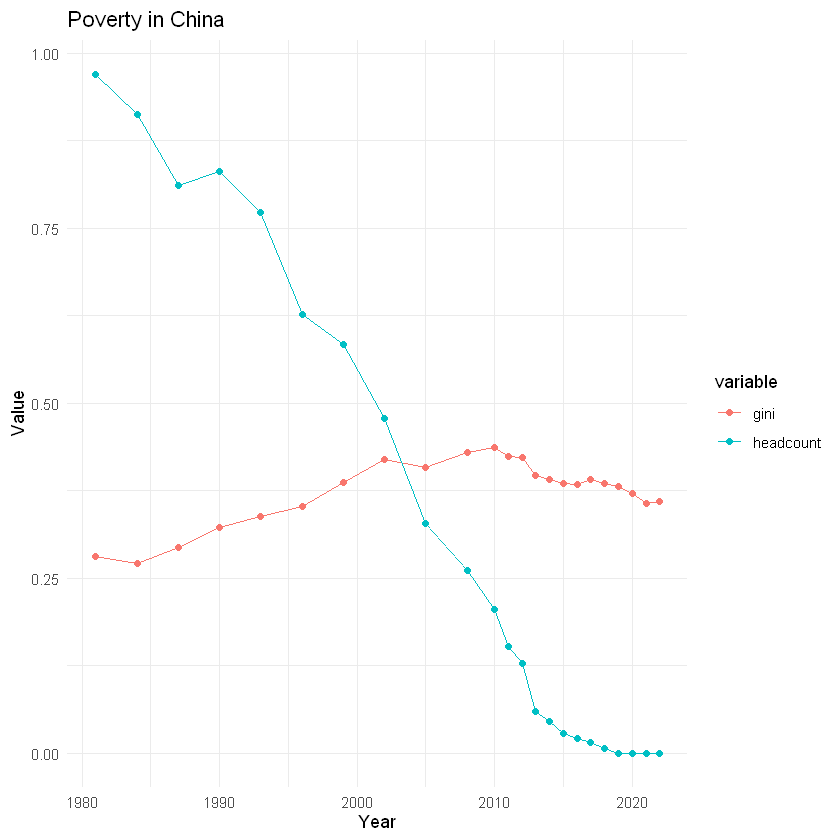

In [152]:
data_China %>% filter(reporting_level == "national") %>%
    pivot_longer(cols = c(headcount, gini), names_to = "variable", values_to = "value") %>%
    ggplot(aes(x = reporting_year, y = value, color = variable)) +
    geom_point() +
    geom_line() +
    theme_minimal() +
    labs(title = "Poverty in China",
         x = "Year",
         y = "Value")

In [ ]:
data_China %>% filter(reporting_year %in% c(1990,2002, 2010, 2019, 2020), reporting_level == "national") %>% #only national
    select(reporting_year, headcount)
data_China %>% filter(reporting_year %in% c(1990,2002, 2010, 2019, 2020), reporting_level %in% c("urban", "rural")) %>%
    select(reporting_year, reporting_level, headcount)
data_China %>% filter(reporting_year %in% c(1990,2002, 2010, 2020), reporting_level %in% c("urban", "rural")) %>%
    select(reporting_level, reporting_year, headcount) %>% arrange(reporting_level)

# gt later for tables

reporting_year,headcount
<int>,<dbl>
1990,0.8310968
2002,0.4779287
2010,0.2058367
2019,0.0000000
2020,0.0000000


reporting_year,reporting_level,headcount
<int>,<chr>,<dbl>
1990,rural,0.91376
1990,urban,0.59820
2002,rural,0.68530
2002,urban,0.15480
2010,rural,0.38785
2010,urban,0.01816
2019,rural,0.00000
2019,urban,0.00000
2020,rural,0.00000


reporting_level,reporting_year,headcount
<chr>,<int>,<dbl>
rural,1990,0.91376
rural,2002,0.68530
rural,2010,0.38785
rural,2020,0.00000
urban,1990,0.59820
urban,2002,0.15480
urban,2010,0.01816
urban,2020,0.00000


[1] 2011
[1] 2019


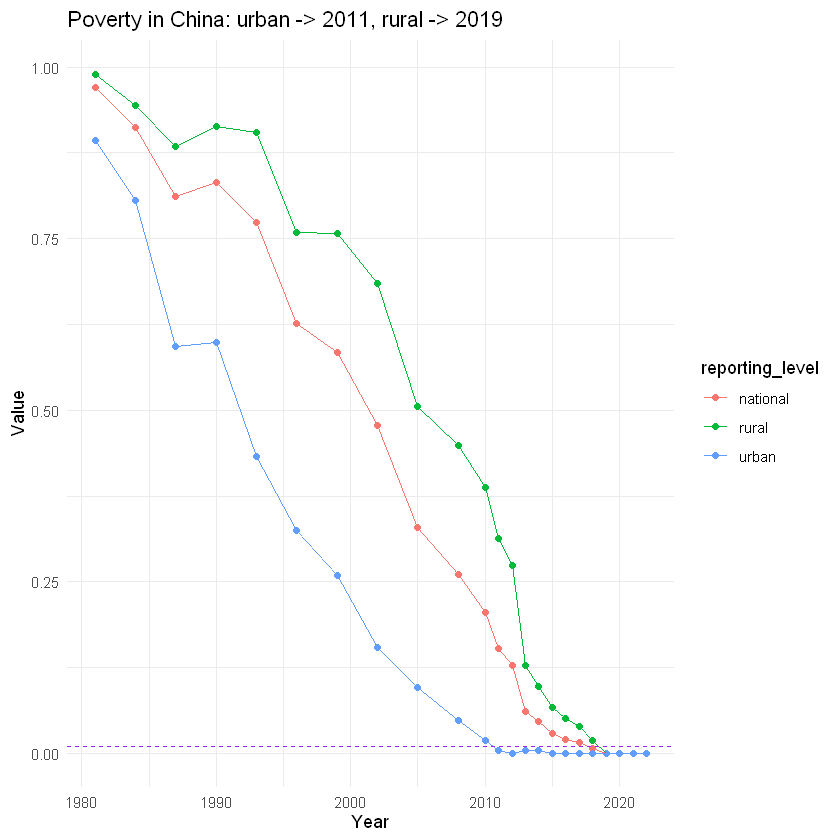

In [ ]:
temp_dat <- data_China %>% filter(reporting_level %in% c("urban", "rural")) %>%
     select(reporting_year, reporting_level, headcount)

temp_dat_urban <- temp_dat %>% filter(reporting_level == "urban") %>% arrange(reporting_year)
for(j in 1:nrow(temp_dat_urban)){
     if(temp_dat_urban[j,"headcount"] < 0.01) {print(temp_dat_urban[j,"reporting_year"]); break} else {
          j = j +1
     }
}
temp_dat_rural <- temp_dat %>% filter(reporting_level == "rural") %>% arrange(reporting_year)
for(j in 1:nrow(temp_dat_rural)){
     if(temp_dat_rural[j,"headcount"] < 0.01) {print(temp_dat_rural[j,"reporting_year"]); break} else {
          j = j +1
     }
}
ggplot(data = data_China, aes(x = reporting_year, y = headcount, color = reporting_level)) +
    geom_point() +
    geom_line() +
    theme_minimal() +
    labs(title = "Poverty in China: urban -> 2011, rural -> 2019",
         x = "Year",
         y = "Value")+
    geom_hline(yintercept = 0.01, linetype = "dashed", color = "purple")


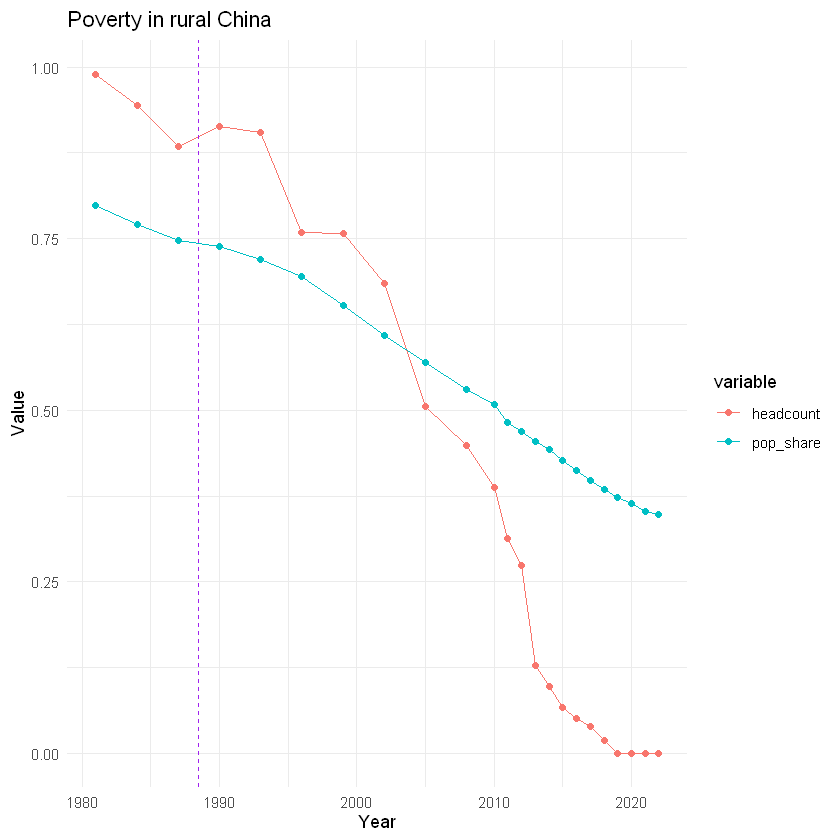

In [132]:
data_China %>% filter(reporting_level == "rural") %>%
    pivot_longer(cols = c(headcount, pop_share), names_to = "variable", values_to = "value") %>%
    ggplot(aes(x = reporting_year, y = value, color = variable)) +
    geom_point() +
    geom_line() +
    theme_minimal() +
    labs(title = "Poverty in rural China",
         x = "Year",
         y = "Value")+
    geom_vline(xintercept = year_change, linetype = "dashed", color = "purple")


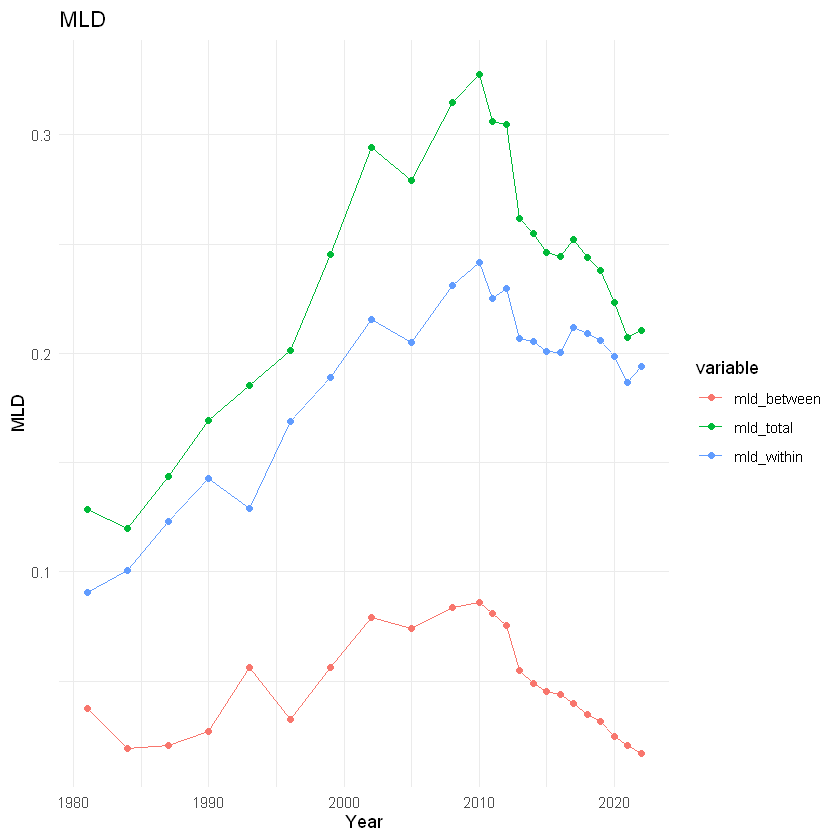

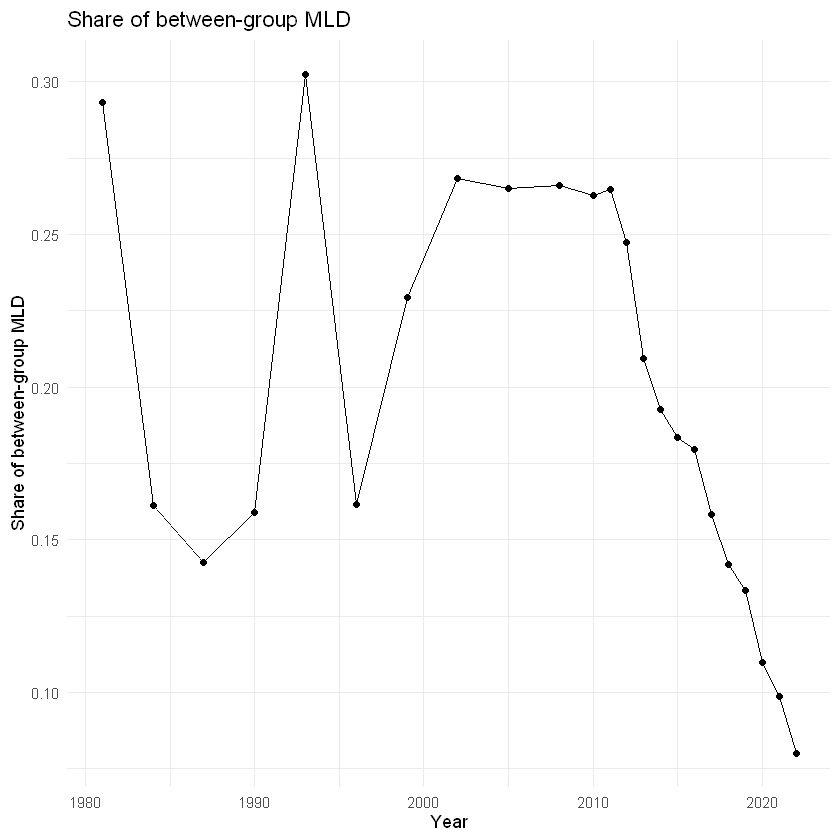

In [274]:
# Plots for MLD
data_mld %>% pivot_longer(cols = c(mld_total, mld_within, mld_between), names_to = "variable", values_to = "value") %>%
    ggplot(aes(x = reporting_year, y = value, color = variable)) +
    geom_point() +
    geom_line() +
    theme_minimal() +
    labs(title = "MLD",
         x = "Year",
         y = "MLD")

ggplot(data = data_mld  , aes (x = reporting_year, y = share_between)) +
    geom_line() +
    geom_point() +
    theme_minimal() +
    labs(title = "Share of between-group MLD",
         x = "Year",
         y = "Share of between-group MLD")


In [ ]:
data_pip$country_name %>% unique() %>% length()
data_pip %>% filter(reporting_level == "national", reporting_year %in% c(1987:1990,2017:2020)) %>% 
    select(region_name, country_name, headcount, reporting_year, welfare_type) %>% {
        function(x) head(x)
    

[1] 172

,region_name,country_name,headcount,reporting_year,welfare_type
,<chr>,<chr>,<dbl>,<int>,<chr>
1,Sub-Saharan Africa,Angola,0.392947051,2018,consumption
2,Europe & Central Asia,Albania,0.014444441,2017,consumption
3,Europe & Central Asia,Albania,0.088681989,2017,income
4,Europe & Central Asia,Albania,0.010100295,2018,consumption
5,Europe & Central Asia,Albania,0.065904681,2018,income
6,Europe & Central Asia,Albania,0.002723695,2019,consumption


In [239]:
ff <- function(pcc, ys){
    if(pcc > 0){
        return(-1+pcc^(1/ys))
    } else {
        pcc <- 1 + abs(pcc)
        return(pcc^(1/ys)-1	)
    }
}
gg <- Vectorize(ff)
data_boxplots <- data_pip %>% filter(welfare_type == "consumption", reporting_level == "national") %>%
    group_by(country_name) %>% summarize(min = min(reporting_year), max = max(reporting_year)) %>%
    ungroup() %>%
    pivot_longer(cols = c("min", "max"), names_to = "kind", values_to = "reporting_year") %>%
    inner_join(., filter(data_pip, welfare_type == "consumption", reporting_level == "national") %>%
    select(region_name, country_name, headcount, reporting_year), by = c("country_name", "reporting_year") ) %>%
    arrange(country_name, reporting_year) %>% pivot_wider(names_from = kind, values_from = c(headcount,reporting_year)) %>%
    mutate(headcount_min = ifelse(headcount_min <= 1e-6, abs(rnorm(1,0,1e-6)),headcount_min)) %>%
    mutate(headcount_max = ifelse(headcount_max <= 1e-6, abs(rnorm(1,0,1e-6)),headcount_max)) %>%
    mutate(pov_change = headcount_max - headcount_min,
    year_span = reporting_year_max - reporting_year_min,
    pov_change_per_year = pov_change/year_span,
    pov_change_percentage = 1 - headcount_max/headcount_min,
    pov_change_percentage_per_year = gg(pov_change_percentage, year_span))

Warning message:
"Removed 10 rows containing non-finite outside the scale range
(`stat_boxplot()`)."


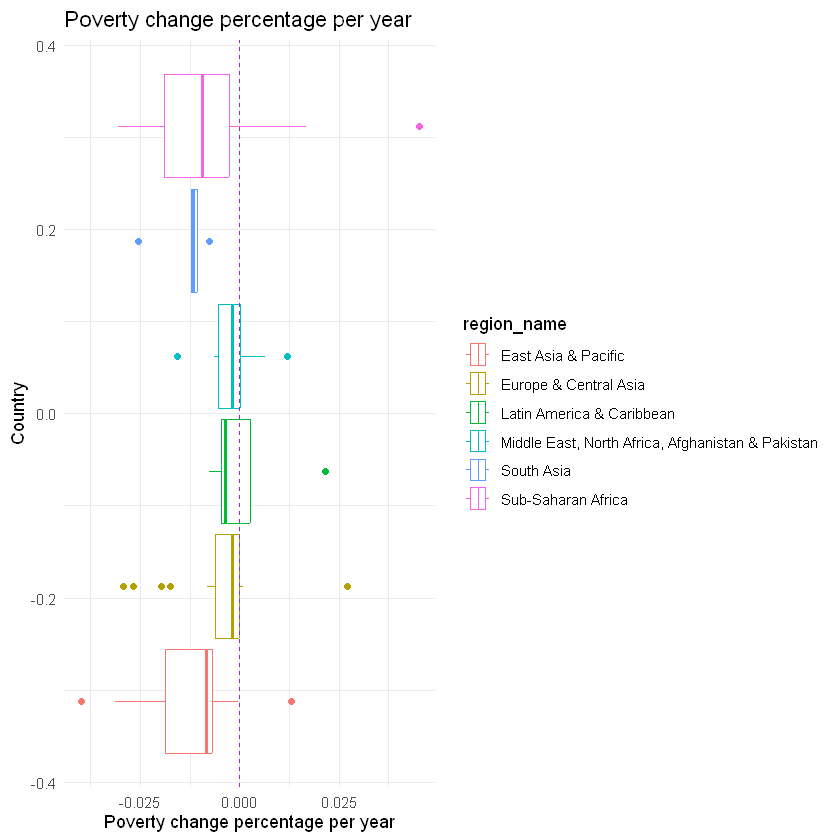

In [269]:
Plot1 <- ggplot(data = data_boxplots, aes(x = pov_change_per_year, color = region_name )) +
    geom_boxplot() +
    theme_minimal() +
    labs(title = "Poverty change percentage per year",
         x = "Poverty change percentage per year",
         y = "Country")+geom_vline(xintercept = 0, linetype = "dashed", color = "purple")
Plot1


In [ ]:
#data_boxplots %>% filter(country_name == "Azerbaijan")

#Sub-Sah -> Sudan (2009->2016) (45% -> 77%)
#South Asia -> Nepal (1995->2022) (71% -> 2%)
#ME -> Yemen (1998->2014) (14% -> 33%), Pakistan (1987->2024) (80% -> 20%)
#Latin -> Peru (1985->1994) (6% -> 26%)
#Europe -> Uzbekistan (1998->2003) (80% -> 93%), Tajikistan (1999->2024) (79% -> 6%)
#East -> China (1990->2022) (83% -> 0%), Indonesia (1984->2025) (86% -> 4%) (Myanmar / Solomon Islands only 2 and 7 years)
#East -> Micronesia (2005->2013) (16% -> 26%)

country_name,region_name,headcount_min,headcount_max,reporting_year_min,reporting_year_max,pov_change,year_span,pov_change_per_year,pov_change_percentage,pov_change_percentage_per_year
<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
Azerbaijan,Europe & Central Asia,0.1965492,2.026385e-06,1995,2005,-0.1965472,10,-0.01965472,0.9999897,-1.030986e-06


In [273]:
data_boxplots %>% filter(pov_change_per_year |> is.na())

country_name,region_name,headcount_min,headcount_max,reporting_year_min,reporting_year_max,pov_change,year_span,pov_change_per_year,pov_change_percentage,pov_change_percentage_per_year
<chr>,<chr>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>
Barbados,Latin America & Caribbean,0.016773976,0.016773976,2016,2016,0,0,NaN,0,0
Equatorial Guinea,Sub-Saharan Africa,0.087941987,0.087941987,2022,2022,0,0,NaN,0,0
Grenada,Latin America & Caribbean,0.007673545,0.007673545,2018,2018,0,0,NaN,0,0
Haiti,Latin America & Caribbean,0.404149905,0.404149905,2012,2012,0,0,NaN,0,0
Marshall Islands,East Asia & Pacific,0.021009586,0.021009586,2019,2019,0,0,NaN,0,0
Nauru,East Asia & Pacific,0.097185745,0.097185745,2012,2012,0,0,NaN,0,0
St. Lucia,Latin America & Caribbean,0.000828510,0.000828510,2015,2015,0,0,NaN,0,0
Suriname,Latin America & Caribbean,0.021780426,0.021780426,2022,2022,0,0,NaN,0,0
Turkmenistan,Europe & Central Asia,0.350758575,0.350758575,1998,1998,0,0,NaN,0,0
